# Predicción de Abandono en Clientes Bancarios
**Ingeniería de Software**

**INTEGRANTES:**
* Zambrano  Luis 

### Planteamiento del problema
La retención de clientes es uno de los mayores desafíos que enfrentan las entidades bancarias en un mercado altamente competitivo. Captar un cliente nuevo puede costar entre cinco y siete veces más que retener a uno existente, por lo que anticipar qué clientes están en riesgo de abandonar la entidad (fenómeno conocido como *churn* o abandono) permite diseñar estrategias de retención focalizadas antes de que la fuga ocurra.

El proyecto plantea una tarea de **clasificación binaria** (aprendizaje supervisado): predecir si un cliente abandonará el banco (`Exited = 1`) o permanecerá (`Exited = 0`).

### Dataset: Bank Customer Churn Modeling
https://www.kaggle.com/datasets/barelydedicated/bank-customer-churn-modeling/data

> **Nota metodológica.** El desbalance de clases (~80/20) se corrige con **SMOTE aplicado únicamente sobre los datos de entrenamiento** (dentro de un `Pipeline`). El conjunto de prueba se mantiene con la distribución real de clientes, para que las métricas reflejen el desempeño esperado en producción y no exista *data leakage*.

## Parte 1: Preprocesamiento de los datos

**Importación de librerías**

In [1]:
# En Google Colab estas librerías ya vienen instaladas. Si falta imblearn, descomenta:
# !pip install -q imbalanced-learn

import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

I0000 00:00:1790739721.116944    1408 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790739721.157205    1408 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1790739722.501350    1408 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


**Carga de datos**

Si el archivo no está en el entorno de Colab, se abrirá el selector para subir `Churn_Modelling.csv`.

In [2]:
rutas = ['Churn_Modelling.csv', '/content/Churn_Modelling.csv', '/content/sample_data/Churn_Modelling.csv']
ruta = next((r for r in rutas if os.path.exists(r)), None)

if ruta is None:
    from google.colab import files          # solo disponible en Colab
    files.upload()
    ruta = 'Churn_Modelling.csv'

df = pd.read_csv(ruta)
print("Dimensiones del dataset original:", df.shape)
df.head()

Dimensiones del dataset original: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**Selección de variables y codificación de `Geography`**

Se eliminan las columnas identificadoras sin valor predictivo (`RowNumber`, `CustomerId`, `Surname`) y se aplica codificación *dummy* (one-hot) a `Geography`. Con `drop_first=True` se generan `Geography_Germany` y `Geography_Spain`; Francia queda como categoría base (ambas en 0).

In [3]:
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'], errors='ignore')
if 'Geography' in df.columns:
    df = pd.get_dummies(df, columns=['Geography'], drop_first=True, dtype=int)

print("Dimensiones tras la selección de variables:", df.shape)
df.head()

Dimensiones tras la selección de variables: (10000, 12)


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,Female,42,2,0.00,1,1,1,101348.88,1,0,0
1,608,Female,41,1,83807.86,1,0,1,112542.58,0,0,1
2,502,Female,42,8,159660.80,3,1,0,113931.57,1,0,0
3,699,Female,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,Female,43,2,125510.82,1,1,1,79084.10,0,0,1


**Limpieza de datos**

In [4]:
print("Valores nulos por columna:\n")
print(df.isnull().sum())
print("\nTotal de registros duplicados:", df.duplicated().sum())
print("Dimensiones actuales:", df.shape)
print("\nDistribución de la variable objetivo (%):")
print((df['Exited'].value_counts(normalize=True) * 100).round(2))

Valores nulos por columna:

CreditScore          0
Gender               0
Age                  0
Tenure               0
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
Geography_Germany    0
Geography_Spain      0
dtype: int64

Total de registros duplicados: 0
Dimensiones actuales: (10000, 12)

Distribución de la variable objetivo (%):
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


**Histogramas (variables cuantitativas)**

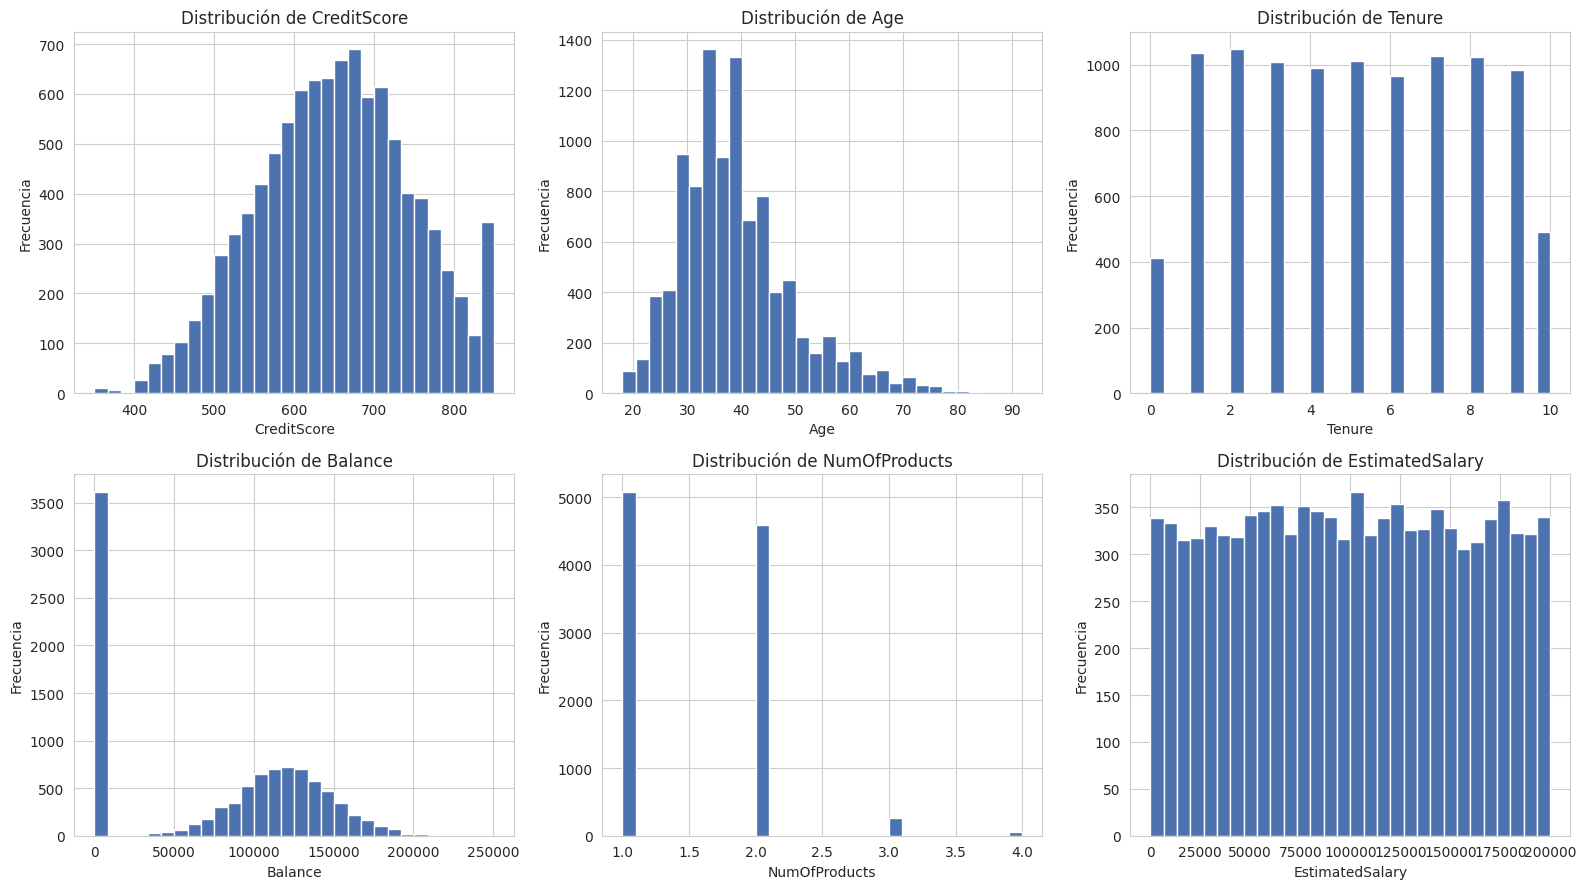

In [5]:
num_vars = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(num_vars):
    axes[i].hist(df[col], bins=30, color='#4C72B0', edgecolor='white')
    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frecuencia')
plt.tight_layout()
plt.savefig('hist_cuantitativas.png', bbox_inches='tight')
plt.show()

**Gráficos de barras (variables categóricas)**

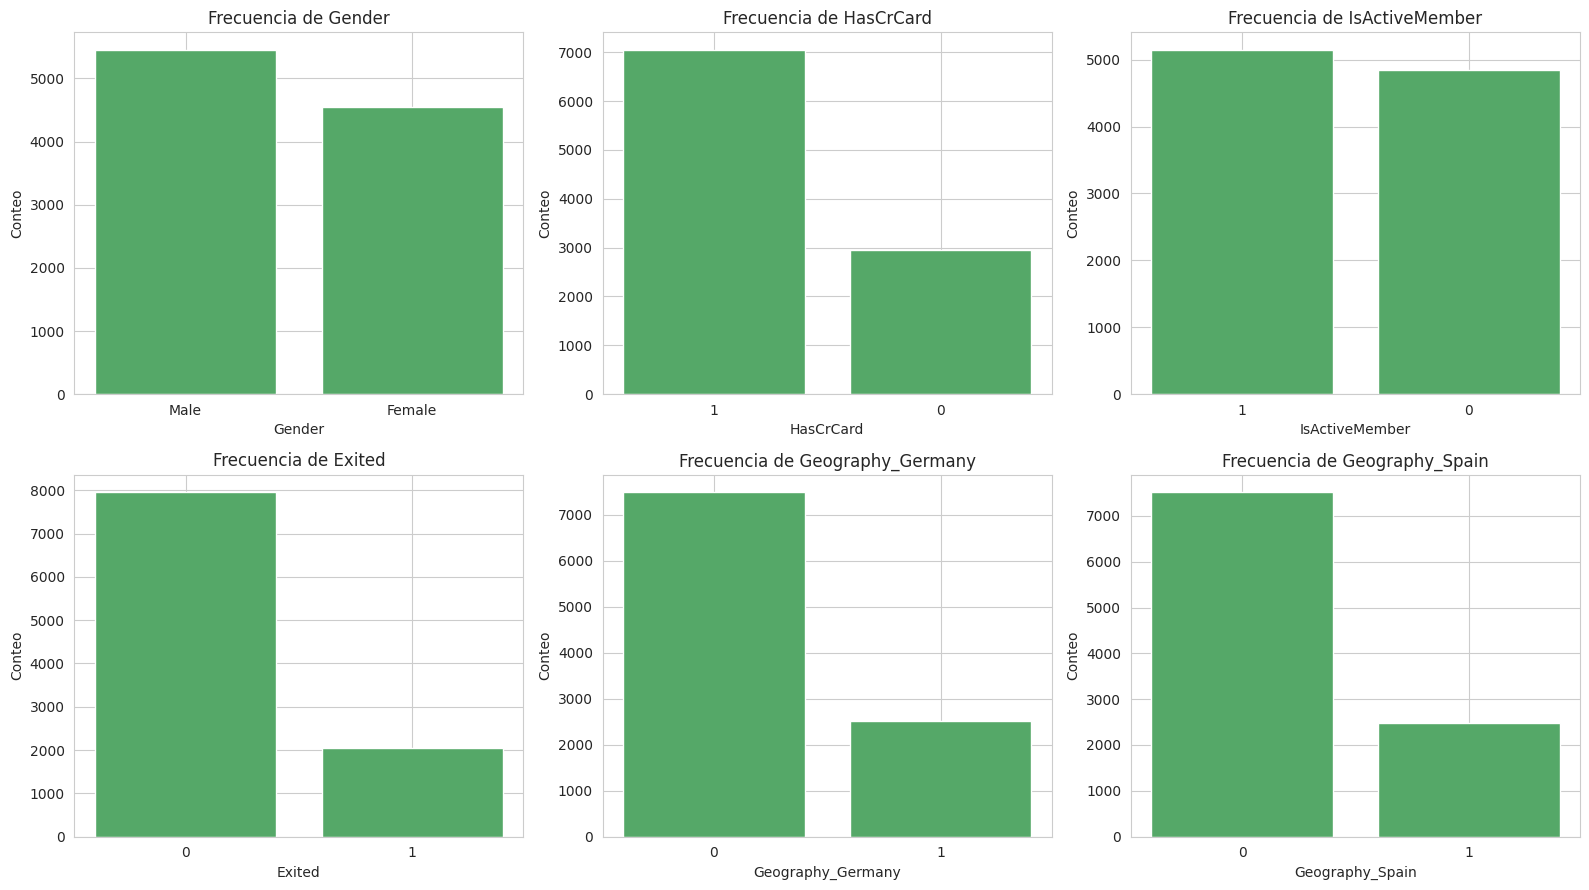

In [6]:
cat_vars = ['Gender', 'HasCrCard', 'IsActiveMember', 'Exited', 'Geography_Germany', 'Geography_Spain']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(cat_vars):
    counts = df[col].value_counts()
    axes[i].bar(counts.index.astype(str), counts.values, color='#55A868')
    axes[i].set_title(f'Frecuencia de {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Conteo')
plt.tight_layout()
plt.savefig('barras_categoricas.png', bbox_inches='tight')
plt.show()

**Análisis bivariado**

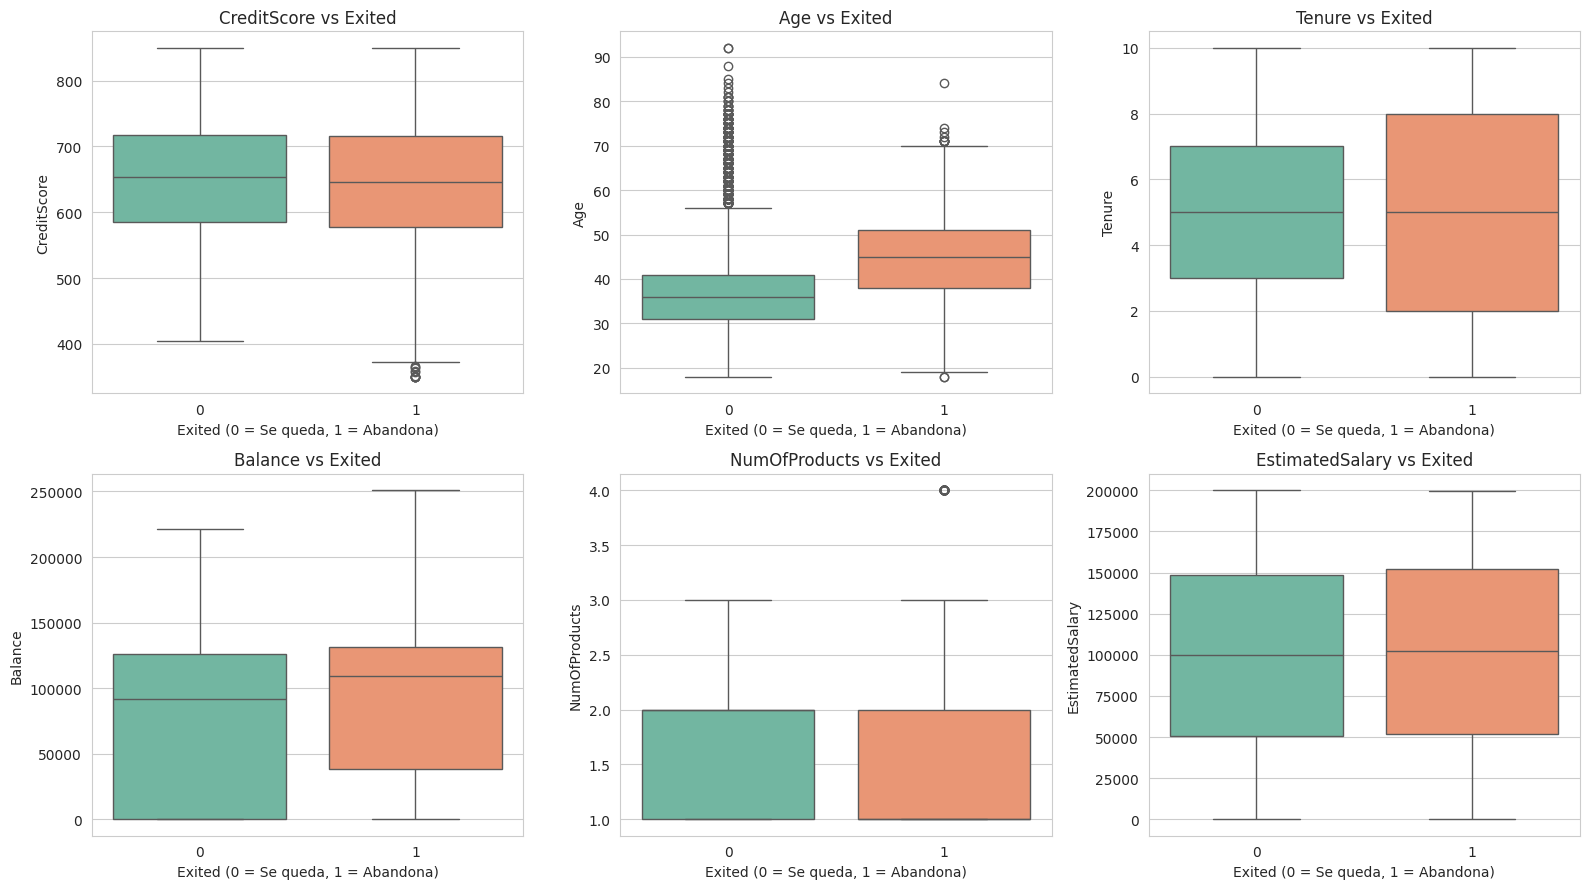

In [7]:
# Numéricas vs Exited (boxplots)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(num_vars):
    sns.boxplot(x='Exited', y=col, hue='Exited', data=df, ax=axes[i], palette='Set2', legend=False)
    axes[i].set_title(f'{col} vs Exited')
    axes[i].set_xlabel('Exited (0 = Se queda, 1 = Abandona)')
plt.tight_layout()
plt.savefig('bivariado_boxplots.png', bbox_inches='tight')
plt.show()

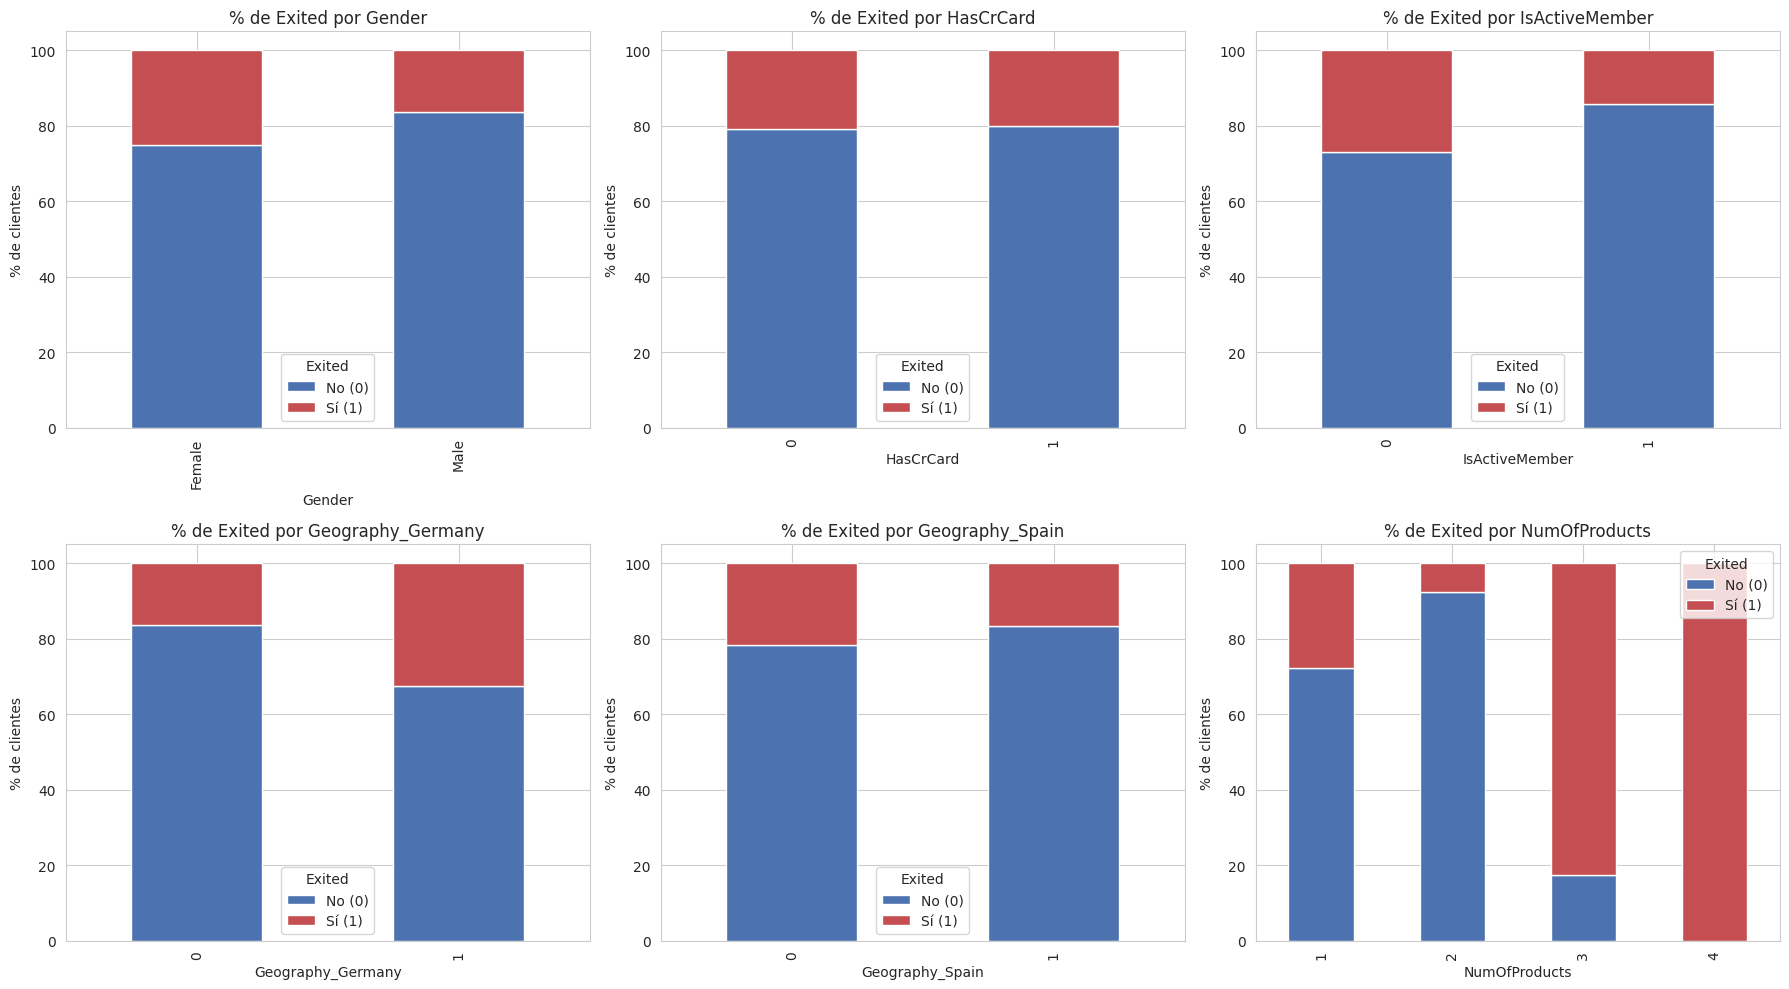

% de abandono por categoría:

Gender
Gender
Female    25.07
Male      16.46

IsActiveMember
IsActiveMember
0    26.85
1    14.27

Geography_Germany
Geography_Germany
0    16.33
1    32.44

HasCrCard
HasCrCard
0    20.81
1    20.18

NumOfProducts
NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00


In [8]:
# Categóricas vs Exited (% de abandono por categoría)
cat_cols = ['Gender', 'HasCrCard', 'IsActiveMember', 'Geography_Germany', 'Geography_Spain', 'NumOfProducts']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    tab = pd.crosstab(df[col], df['Exited'], normalize='index') * 100
    tab.plot(kind='bar', stacked=True, ax=axes[i], color=['#4C72B0', '#C44E52'])
    axes[i].set_title(f'% de Exited por {col}')
    axes[i].set_ylabel('% de clientes')
    axes[i].legend(title='Exited', labels=['No (0)', 'Sí (1)'])
plt.tight_layout()
plt.savefig('bivariado_categoricas.png', bbox_inches='tight')
plt.show()

print("% de abandono por categoría:")
for col in ['Gender', 'IsActiveMember', 'Geography_Germany', 'HasCrCard', 'NumOfProducts']:
    print(f"\n{col}")
    print((df.groupby(col)['Exited'].mean() * 100).round(2).to_string())

**Boxplots y detección de outliers (regla IQR)**

Un valor es atípico si queda fuera de `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`.

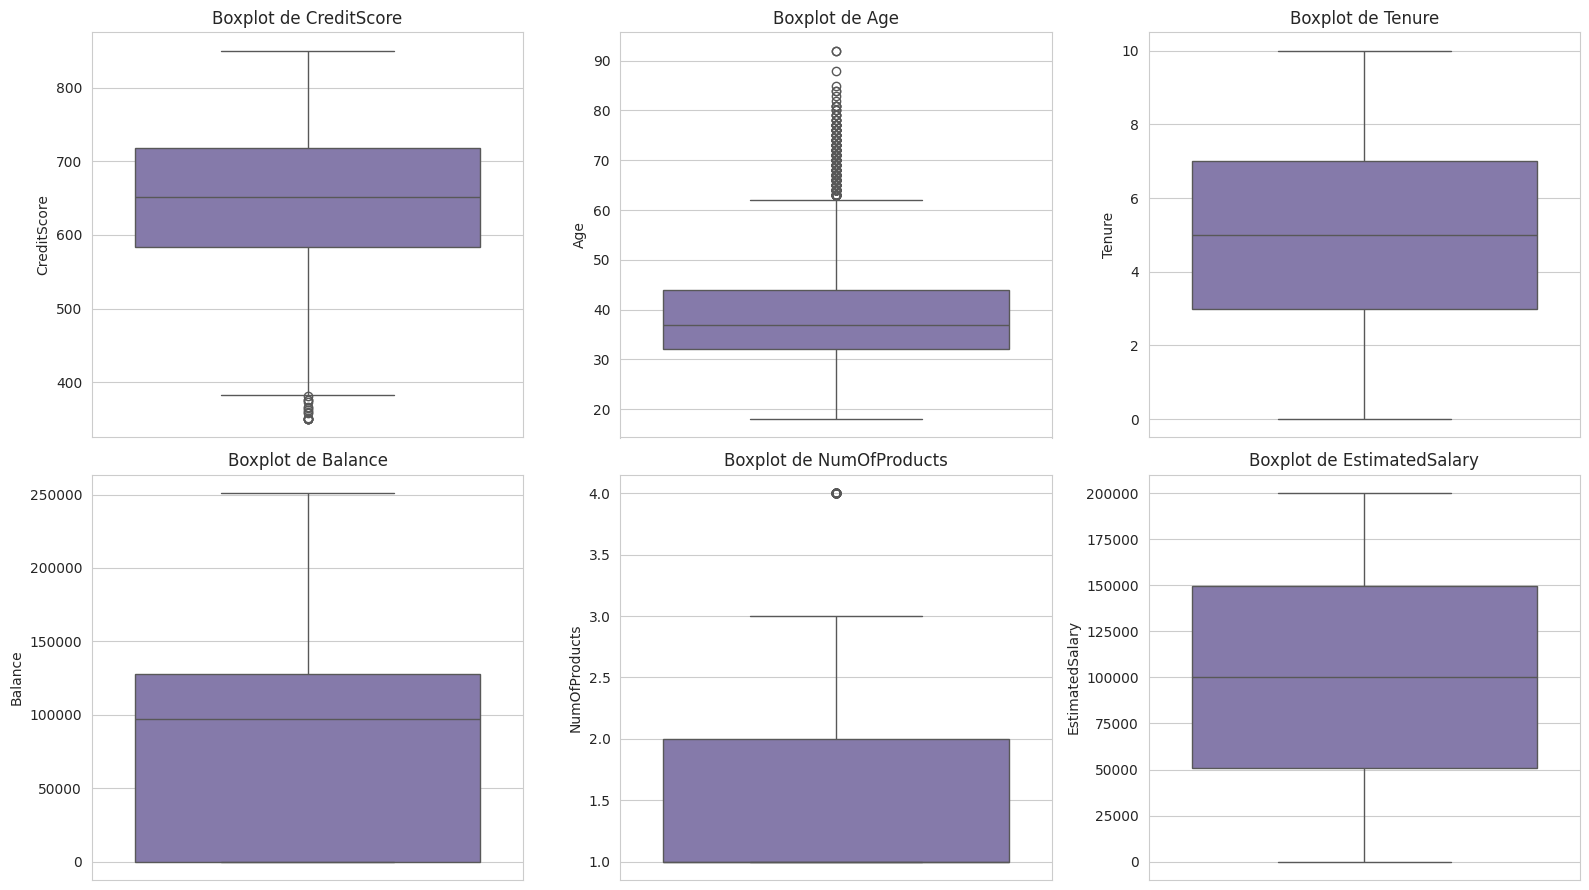

,Variable,Límite inf.,Límite sup.,N° outliers,% outliers
0,CreditScore,383.00,919.00,15,0.15
1,Age,14.00,62.00,359,3.59
2,Tenure,-3.00,13.00,0,0.00
3,Balance,-191466.36,319110.60,0,0.00
4,NumOfProducts,-0.50,3.50,60,0.60
5,EstimatedSalary,-96577.10,296967.45,0,0.00


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(num_vars):
    sns.boxplot(y=df[col], ax=axes[i], color='#8172B2')
    axes[i].set_title(f'Boxplot de {col}')
plt.tight_layout()
plt.savefig('boxplots_outliers.png', bbox_inches='tight')
plt.show()

def resumen_outliers_iqr(data, cols):
    resumen = []
    for col in cols:
        Q1, Q3 = data[col].quantile(0.25), data[col].quantile(0.75)
        IQR = Q3 - Q1
        lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
        n_out = ((data[col] < lim_inf) | (data[col] > lim_sup)).sum()
        resumen.append([col, round(lim_inf, 2), round(lim_sup, 2), n_out, round(100 * n_out / len(data), 2)])
    return pd.DataFrame(resumen, columns=['Variable', 'Límite inf.', 'Límite sup.', 'N° outliers', '% outliers'])

resumen_outliers_iqr(df, num_vars)

**Decisión sobre los outliers.** Los valores atípicos corresponden a clientes reales (p. ej. edades de 62–92 años), no a errores de captura, por lo que **no se eliminan**. Se debe tener presente que `StandardScaler` *no* neutraliza los outliers (la media y la desviación estándar son sensibles a ellos); se conserva porque la proporción de atípicos es baja y los modelos basados en árboles no dependen de la escala.

## Parte 2: Selección y transformación de variables

**Correlación de Pearson**

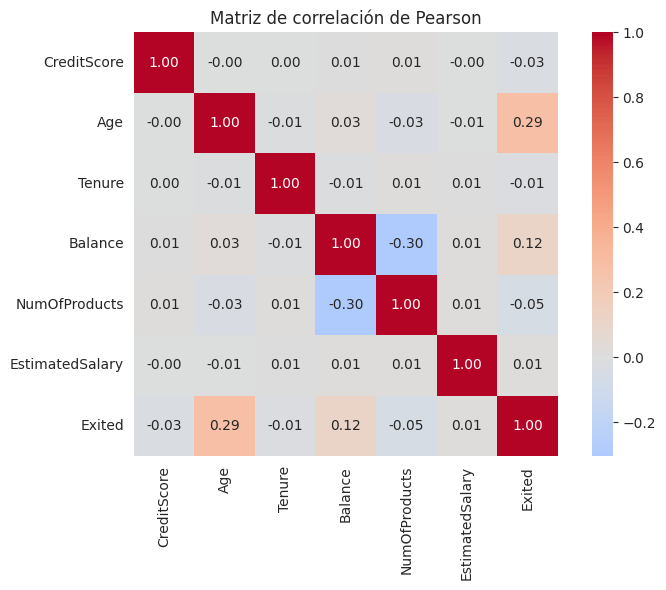

Age                0.2853
Balance            0.1185
NumOfProducts     -0.0478
CreditScore       -0.0271
Tenure            -0.0140
EstimatedSalary    0.0121
Name: Exited, dtype: float64


In [10]:
corr_matrix = df[num_vars + ['Exited']].corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Matriz de correlación de Pearson')
plt.tight_layout()
plt.savefig('correlacion_pearson.png', bbox_inches='tight')
plt.show()

corr_target = corr_matrix['Exited'].drop('Exited').sort_values(key=abs, ascending=False)
print(corr_target.round(4))

**Prueba Chi-cuadrado**

In [11]:
cat_features = ['Geography_Germany', 'Geography_Spain', 'Gender', 'HasCrCard', 'IsActiveMember']

resultados_chi2 = []
for col in cat_features:
    tabla = pd.crosstab(df[col], df['Exited'])
    chi2_stat, p_value, dof, expected = chi2_contingency(tabla)
    resultados_chi2.append([col, round(chi2_stat, 3), round(p_value, 5),
                            "Significativa (p<0.05)" if p_value < 0.05 else "No significativa"])

df_chi2 = pd.DataFrame(resultados_chi2, columns=['Variable', 'Chi2', 'p-valor', 'Conclusión'])
df_chi2.sort_values('Chi2', ascending=False)

,Variable,Chi2,p-valor,Conclusión
0,Geography_Germany,299.988,0.00000,Significativa (p<0.05)
4,IsActiveMember,242.985,0.00000,Significativa (p<0.05)
2,Gender,112.919,0.00000,Significativa (p<0.05)
1,Geography_Spain,27.436,0.00000,Significativa (p<0.05)
3,HasCrCard,0.471,0.49237,No significativa


**Transformación de variables categóricas** (`Gender` con `LabelEncoder`; `Geography` ya codificada con dummies).

In [12]:
df_encoded = df.copy()

if not pd.api.types.is_numeric_dtype(df_encoded['Gender']):
    le = LabelEncoder()
    df_encoded['Gender'] = le.fit_transform(df_encoded['Gender'])
    print("Mapeo de Gender:", dict(zip(le.classes_, le.transform(le.classes_))))

df_encoded.to_csv('churn_preprocesado.csv', index=False)
print("Dimensiones finales:", df_encoded.shape)
print("Tipos de datos:", df_encoded.dtypes.unique())
df_encoded.head()

Mapeo de Gender: {'Female': np.int64(0), 'Male': np.int64(1)}
Dimensiones finales: (10000, 12)
Tipos de datos: [dtype('int64') dtype('float64')]


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,1


## Parte 3: Modelado y evaluación de algoritmos de aprendizaje supervisado

**Partición estratificada 80/20.** Se divide *antes* de aplicar SMOTE o escalar, de modo que el conjunto de prueba conserve la proporción real de clases y no contenga información sintética.

In [13]:
X = df_encoded.drop(columns=['Exited'])
y = df_encoded['Exited']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("% churn en train:", round(y_train.mean() * 100, 2), "| % churn en test:", round(y_test.mean() * 100, 2))
print("Accuracy de referencia (predecir siempre 'se queda'):", round(1 - y_test.mean(), 4))

Train: (8000, 11) | Test: (2000, 11)
% churn en train: 20.38 | % churn en test: 20.35
Accuracy de referencia (predecir siempre 'se queda'): 0.7965


**Optimización con `GridSearchCV` dentro de un `Pipeline`**

El *pipeline* aplica `StandardScaler` → `SMOTE` → modelo. Al usarlo dentro de la validación cruzada, SMOTE se ejecuta solo sobre los pliegues de entrenamiento de cada iteración, y el pliegue de validación permanece sin sintetizar. Se optimiza por **F1** (clase 1) porque el objetivo es detectar bien a quienes abandonan y el accuracy es engañoso con clases desbalanceadas.

In [14]:
modelos = {
    'Regresión Logística': (LogisticRegression(max_iter=1000, random_state=SEED),
                            {'clf__C': [0.01, 0.1, 1, 10]}),
    'KNN': (KNeighborsClassifier(),
            {'clf__n_neighbors': [3, 5, 7, 9, 11, 15]}),
    'Árbol de Decisión': (DecisionTreeClassifier(random_state=SEED),
                          {'clf__max_depth': [3, 5, 7, 10, 15]})
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
mejores = {}

for nombre, (modelo, params) in modelos.items():
    print(f"\n--- Optimizando {nombre} ---")
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('smote', SMOTE(random_state=SEED)),
                     ('clf', modelo)])
    gs = GridSearchCV(pipe, params, cv=cv, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    mejores[nombre] = gs.best_estimator_

    print("Mejores parámetros:", gs.best_params_)
    print(f"F1 medio en validación cruzada: {gs.best_score_:.4f}")
    y_pred = gs.predict(X_test)
    print(f"Accuracy en test: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred, target_names=['Se queda (0)', 'Abandona (1)']))


--- Optimizando Regresión Logística ---


Mejores parámetros: {'clf__C': 0.01}
F1 medio en validación cruzada: 0.4883
Accuracy en test: 0.7180
              precision    recall  f1-score   support

Se queda (0)       0.90      0.72      0.80      1593
Abandona (1)       0.39      0.70      0.50       407

    accuracy                           0.72      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.72      0.74      2000


--- Optimizando KNN ---


Mejores parámetros: {'clf__n_neighbors': 15}
F1 medio en validación cruzada: 0.5326
Accuracy en test: 0.7395
              precision    recall  f1-score   support

Se queda (0)       0.91      0.75      0.82      1593
Abandona (1)       0.42      0.70      0.52       407

    accuracy                           0.74      2000
   macro avg       0.66      0.72      0.67      2000
weighted avg       0.81      0.74      0.76      2000


--- Optimizando Árbol de Decisión ---


Mejores parámetros: {'clf__max_depth': 5}
F1 medio en validación cruzada: 0.5686
Accuracy en test: 0.7950
              precision    recall  f1-score   support

Se queda (0)       0.92      0.82      0.86      1593
Abandona (1)       0.50      0.70      0.58       407

    accuracy                           0.80      2000
   macro avg       0.71      0.76      0.72      2000
weighted avg       0.83      0.80      0.81      2000



**Explicación del código.** Se divide el dataset de forma estratificada y, para cada algoritmo (Regresión Logística, KNN y Árbol de Decisión), se construye un `Pipeline` con escalamiento, SMOTE y el clasificador. `GridSearchCV` con validación cruzada estratificada de 5 pliegues elige los hiperparámetros que maximizan el F1 de la clase minoritaria. Al final, cada modelo se evalúa en un conjunto de prueba **no balanceado y sin datos sintéticos**.

## Parte 4: Redes Neuronales Artificiales (MLP)

Se diseña un perceptrón multicapa con dos capas ocultas, regularización L2, Dropout y EarlyStopping. Para evitar *leakage*, se ajusta el escalador solo con el entrenamiento, se separa una **validación real** (sin datos sintéticos) y SMOTE se aplica únicamente al bloque de ajuste.

In [15]:
scaler_mlp = StandardScaler().fit(X_train)
X_tr_all = scaler_mlp.transform(X_train)
X_te = scaler_mlp.transform(X_test)

# Validación real (distribución original) separada ANTES de SMOTE
X_fit, X_val, y_fit, y_val = train_test_split(
    X_tr_all, y_train, test_size=0.2, stratify=y_train, random_state=SEED)

# SMOTE solo sobre el bloque de ajuste
X_fit, y_fit = SMOTE(random_state=SEED).fit_resample(X_fit, y_fit)
print("Ajuste (tras SMOTE):", X_fit.shape, "| % churn:", round(np.mean(y_fit) * 100, 1))
print("Validación:", X_val.shape, "| % churn:", round(np.mean(y_val) * 100, 1))

Ajuste (tras SMOTE): (10192, 11) | % churn: 50.0
Validación: (1600, 11) | % churn: 20.4


In [16]:
tf.random.set_seed(SEED)

mlp_model = Sequential([
    Input(shape=(X_fit.shape[1],)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(0.2),
    Dense(32, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

mlp_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = mlp_model.fit(
    X_fit, y_fit,
    epochs=100, batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=2
)

Epoch 1/100


319/319 - 2s - 6ms/step - accuracy: 0.6964 - loss: 0.8745 - val_accuracy: 0.7262 - val_loss: 0.6642


Epoch 2/100


319/319 - 1s - 4ms/step - accuracy: 0.7531 - loss: 0.6125 - val_accuracy: 0.7694 - val_loss: 0.5547


Epoch 3/100


319/319 - 1s - 2ms/step - accuracy: 0.7652 - loss: 0.5570 - val_accuracy: 0.7875 - val_loss: 0.5171


... (82 outputs left out)

Epoch 45/100


319/319 - 1s - 2ms/step - accuracy: 0.8009 - loss: 0.4724 - val_accuracy: 0.8119 - val_loss: 0.4503


Epoch 46/100


319/319 - 1s - 2ms/step - accuracy: 0.7955 - loss: 0.4729 - val_accuracy: 0.8081 - val_loss: 0.4585


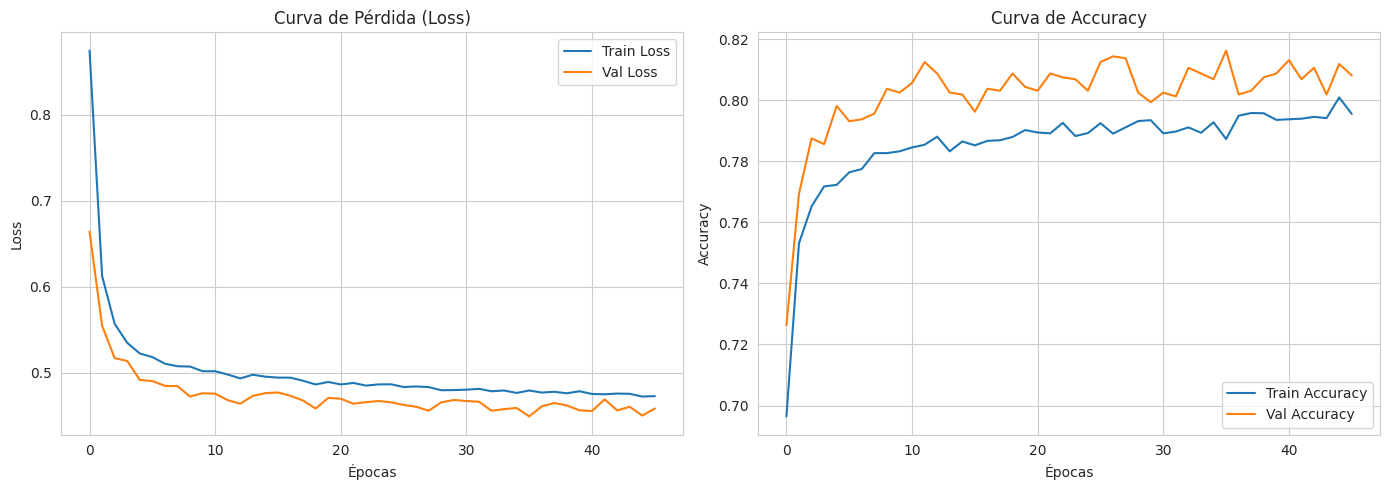

Épocas entrenadas: 46 | mejor época: 36
En la mejor época -> Train loss: 0.4794 | Val loss: 0.4493
                     Train acc:  0.7873 | Val acc:  0.8163


In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['loss'], label='Train Loss')
ax1.plot(history.history['val_loss'], label='Val Loss')
ax1.set_title('Curva de Pérdida (Loss)'); ax1.set_xlabel('Épocas'); ax1.set_ylabel('Loss'); ax1.legend()

ax2.plot(history.history['accuracy'], label='Train Accuracy')
ax2.plot(history.history['val_accuracy'], label='Val Accuracy')
ax2.set_title('Curva de Accuracy'); ax2.set_xlabel('Épocas'); ax2.set_ylabel('Accuracy'); ax2.legend()

plt.tight_layout()
plt.savefig('curvas_mlp.png', bbox_inches='tight')
plt.show()

mejor = int(np.argmin(history.history['val_loss']))
print(f"Épocas entrenadas: {len(history.history['loss'])} | mejor época: {mejor + 1}")
print(f"En la mejor época -> Train loss: {history.history['loss'][mejor]:.4f} | Val loss: {history.history['val_loss'][mejor]:.4f}")
print(f"                     Train acc:  {history.history['accuracy'][mejor]:.4f} | Val acc:  {history.history['val_accuracy'][mejor]:.4f}")

In [18]:
loss, accuracy = mlp_model.evaluate(X_te, y_test, verbose=0)
print(f"Resultados en Test -> Loss: {loss:.4f} | Accuracy: {accuracy:.4f}")

y_score_mlp = mlp_model.predict(X_te, verbose=0).ravel()
y_pred_mlp = (y_score_mlp >= 0.5).astype(int)
print("\nReporte de Clasificación MLP:")
print(classification_report(y_test, y_pred_mlp, target_names=['Se queda (0)', 'Abandona (1)']))

Resultados en Test -> Loss: 0.4397 | Accuracy: 0.8165

Reporte de Clasificación MLP:
              precision    recall  f1-score   support

Se queda (0)       0.92      0.85      0.88      1593
Abandona (1)       0.54      0.69      0.61       407

    accuracy                           0.82      2000
   macro avg       0.73      0.77      0.74      2000
weighted avg       0.84      0.82      0.82      2000



## Parte 5: Comparación de modelos

Los cuatro modelos se evalúan sobre el **mismo conjunto de prueba**, con la distribución real de clases. La tabla se calcula con código (sin valores escritos a mano).

In [19]:
probas = {n: m.predict_proba(X_test)[:, 1] for n, m in mejores.items()}
probas['MLP'] = y_score_mlp

filas = []
for n, p in probas.items():
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas.append([n, accuracy_score(y_test, pred), precision_score(y_test, pred),
                  recall_score(y_test, pred), f1_score(y_test, pred),
                  roc_auc_score(y_test, p), fp / (fp + tn), fn / (fn + tp)])

comparativa = pd.DataFrame(filas, columns=['Modelo', 'Accuracy', 'Precisión (c1)', 'Recall (c1)',
                                           'F1 (c1)', 'AUC', 'FPR', 'FNR']).round(4)
comparativa = comparativa.sort_values('F1 (c1)', ascending=False).reset_index(drop=True)
print("TABLA COMPARATIVA DE MODELOS (conjunto de prueba, n =", len(y_test), ")")
comparativa

TABLA COMPARATIVA DE MODELOS (conjunto de prueba, n = 2000 )


,Modelo,Accuracy,Precisión (c1),Recall (c1),F1 (c1),AUC,FPR,FNR
0,MLP,0.8165,0.5382,0.6929,0.6058,0.8654,0.1519,0.3071
1,Árbol de Decisión,0.7950,0.4974,0.7027,0.5825,0.8280,0.1814,0.2973
2,KNN,0.7395,0.4167,0.7002,0.5225,0.7933,0.2505,0.2998
3,Regresión Logística,0.7180,0.3920,0.7002,0.5026,0.7765,0.2775,0.2998


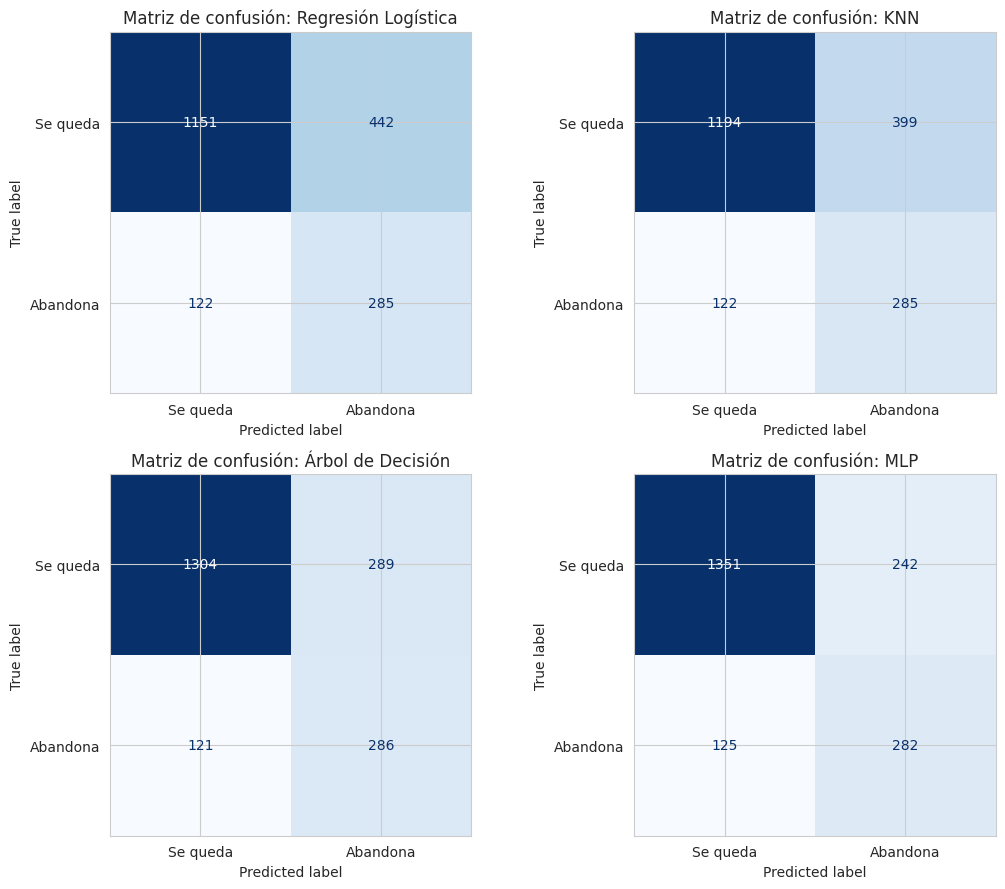

In [20]:
# Matrices de confusión de los 4 modelos
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (n, p) in zip(axes.flatten(), probas.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['Se queda', 'Abandona']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Matriz de confusión: {n}')
plt.tight_layout()
plt.savefig('matrices_confusion.png', bbox_inches='tight')
plt.show()

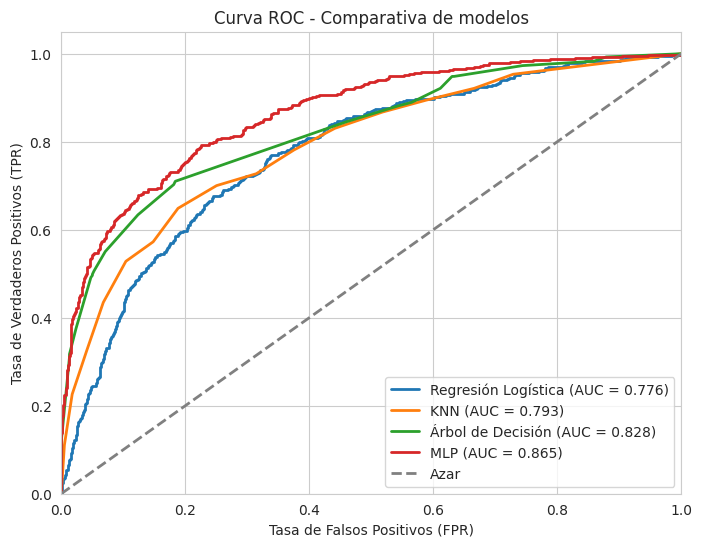

In [21]:
# Curvas ROC comparativas
plt.figure(figsize=(8, 6))
for n, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f'{n} (AUC = {roc_auc_score(y_test, p):.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Azar')
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Comparativa de modelos')
plt.legend(loc='lower right')
plt.savefig('roc_comparativa.png', bbox_inches='tight')
plt.show()

## Conclusiones

> Las cifras citadas corresponden a la ejecución de referencia (`random_state = 42`, conjunto de prueba de 2 000 clientes con ≈ 20 % de churn). Si al ejecutar en Colab hay pequeñas variaciones por la versión de las librerías, actualiza los valores con la tabla comparativa de la Parte 5.

**1. Calidad de los datos.** El dataset tiene 10 000 registros y 12 variables tras eliminar `RowNumber`, `CustomerId` y `Surname`; no presenta nulos ni duplicados. El máximo de valores atípicos según IQR es 3.59 % (`Age`) y corresponde a clientes reales, por lo que se conservaron.

**2. Variables asociadas al abandono.** Pearson, Chi-cuadrado y el análisis bivariado coinciden en `Age` (r = 0.285), `Balance` (r = 0.119), `IsActiveMember` (26.9 % de abandono en inactivos frente a 14.3 % en activos), `Geography_Germany` (32.4 % frente a 16.3 %) y `Gender` (25.1 % en mujeres frente a 16.5 % en hombres). `NumOfProducts` tiene una correlación lineal débil (−0.048), pero su relación es claramente no lineal: el abandono es 27.7 % con 1 producto, 7.6 % con 2, 82.7 % con 3 y 100 % con 4. `HasCrCard` no es significativa (p = 0.492).

**3. Desbalance y prevención de *data leakage*.** Como ≈ 80 % de los clientes permanece, un modelo que siempre prediga "se queda" ya obtiene un accuracy de 0.7965. Por eso el accuracy no basta para comparar modelos y se priorizan recall, F1 y AUC de la clase "Abandona". SMOTE se aplicó solo sobre los datos de entrenamiento (dentro del `Pipeline` y del bloque de ajuste del MLP), y el conjunto de prueba conservó la distribución real. Esto reduce las métricas respecto a un flujo con SMOTE previo a la partición, pero las vuelve representativas del desempeño esperado en producción.

**4. Comparación de modelos (conjunto de prueba).**

| Modelo | Accuracy | Precisión (c1) | Recall (c1) | F1 (c1) | AUC |
| --- | --- | --- | --- | --- | --- |
| MLP | 0.8165 | 0.538 | 0.693 | 0.606 | 0.865 |
| Árbol de Decisión (depth = 5) | 0.7950 | 0.497 | 0.703 | 0.583 | 0.828 |
| KNN (k = 15) | 0.7395 | 0.417 | 0.700 | 0.523 | 0.793 |
| Regresión Logística (C = 0.01) | 0.7180 | 0.392 | 0.700 | 0.503 | 0.777 |

El MLP obtiene el mejor F1 y el mejor AUC, con la menor tasa de falsos positivos (15.2 %, frente a 18.1 % del árbol). Los cuatro modelos detectan aproximadamente el 70 % de los clientes que abandonan (recall similar), de modo que la diferencia está en la precisión: el MLP genera menos alertas erróneas. La Regresión Logística, por ser lineal, es la que peor captura relaciones como la de `NumOfProducts` o `Age`.

**5. Sobreajuste del MLP.** El entrenamiento se detuvo por *EarlyStopping* en la época 46 y restauró los pesos de la época 36. En ese punto la pérdida de validación (0.449) es menor que la de entrenamiento (0.479), y en test la pérdida es 0.440, sin señales de sobreajuste. (El accuracy de entrenamiento se calcula sobre datos balanceados con SMOTE, por lo que no es directamente comparable con el de validación.)

**6. Alcance y limitaciones.** Con una precisión cercana a 0.54, aproximadamente la mitad de los clientes marcados por el mejor modelo no abandonaría el banco; el modelo sirve para priorizar campañas de retención, no para decisiones automáticas. Las diferencias entre modelos se midieron sobre una única partición de prueba; para confirmarlas convendría repetir con validación cruzada. Además, el umbral de 0.5 es ajustable: bajarlo aumenta el recall a costa de más falsos positivos.

**7. Recomendación.** Se recomienda el **MLP** por su mejor F1 y AUC. Si el banco necesita explicar por qué un cliente fue marcado como en riesgo, el **Árbol de Decisión** (profundidad 5) es una alternativa más interpretable con un F1 solo 0.02 menor. Los segmentos de mayor riesgo son clientes de mayor edad, con saldo alto, residentes en Alemania, inactivos y con 3 o 4 productos.

**8. Trabajo futuro.** Incorporar variables de comportamiento transaccional (uso de la app, reclamos, contactos con atención al cliente), probar modelos de ensamble (Random Forest, Gradient Boosting) con validación cruzada, ajustar el umbral de decisión según el costo de retención, y aplicar técnicas de interpretabilidad (SHAP, LIME).